# Module 1 — Data Understanding

**Đề tài:** Traffic Accident Severity Prediction (US Accidents)
**Môn:** DAP391m — AI & Data Science with Python & SQL, Fall 2026
**Lớp:** AI2003 — Giảng viên: Lê Nhật Tùng
**Nhóm:** Group 7
**Thành viên:**
- Lê Huy Hùng — SE204967
- Nguyễn Thiện Nhân — SE203924
- Đặng Gia Bảo — SE203977

**Bộ dữ liệu:** US Accidents (2016–2023) — Sobhan Moosavi, Kaggle (~7.7 triệu dòng, 46 cột)
Link: https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents
Giấy phép: CC BY-NC-SA 4.0

**Biến mục tiêu:** `Severity` (1 = nhẹ nhất, 4 = nghiêm trọng nhất)

---

### Pipeline của notebook này (Module 1 — Data Understanding)
1. Hiểu dữ liệu (Data Understanding)
2. Khám phá dữ liệu (Exploratory Data Analysis)
3. Xử lý Missing Data
4. Xử lý Outliers
5. Feature Engineering (tạo đặc trưng)
6. Xử lý dữ liệu trùng lặp
7. Kiểm tra và validate kết quả
8. Lưu dữ liệu sạch

> Output của notebook: `cleaned_us_accidents.csv` — dùng cho Module 2 (SQL & Python nâng cao), Module 3 (Visualization), Module 5 (Modeling cho RQ2).

## Bước 0. Setup & Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['font.size'] = 10

print('Libraries imported successfully.')

Libraries imported successfully.


## BƯỚC 1 — Hiểu dữ liệu (Data Understanding)

### 1.1. Load dữ liệu


In [2]:
df = pd.read_csv('US_Accidents_March23.csv', low_memory=False)
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head()

Dataset shape: 7,728,394 rows × 46 columns


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,Right lane blocked due to accident on I-70 Eas...,I-70 E,Dayton,Montgomery,OH,45424,US,US/Eastern,KFFO,2016-02-08 05:58:00,36.9,NaN,91.0,29.68,10.0,Calm,NaN,0.02,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,Accident on Brice Rd at Tussing Rd. Expect del...,Brice Rd,Reynoldsburg,Franklin,OH,43068-3402,US,US/Eastern,KCMH,2016-02-08 05:51:00,37.9,NaN,100.0,29.65,10.0,Calm,NaN,0.00,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,Accident on OH-32 State Route 32 Westbound at ...,State Route 32,Williamsburg,Clermont,OH,45176,US,US/Eastern,KI69,2016-02-08 06:56:00,36.0,33.3,100.0,29.67,10.0,SW,3.5,NaN,Overcast,False,False,False,False,False,False,False,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,Accident on I-75 Southbound at Exits 52 52B US...,I-75 S,Dayton,Montgomery,OH,45417,US,US/Eastern,KDAY,2016-02-08 07:38:00,35.1,31.0,96.0,29.64,9.0,SW,4.6,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,Accident on McEwen Rd at OH-725 Miamisburg Cen...,Miamisburg Centerville Rd,Dayton,Montgomery,OH,45459,US,US/Eastern,KMGY,2016-02-08 07:53:00,36.0,33.3,89.0,29.65,6.0,SW,3.5,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day


### 1.2. Cấu trúc dữ liệu và kiểu dữ liệu

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7728394 entries, 0 to 7728393
Data columns (total 46 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   ID                     object 
 1   Source                 object 
 2   Severity               int64  
 3   Start_Time             object 
 4   End_Time               object 
 5   Start_Lat              float64
 6   Start_Lng              float64
 7   End_Lat                float64
 8   End_Lng                float64
 9   Distance(mi)           float64
 10  Description            object 
 11  Street                 object 
 12  City                   object 
 13  County                 object 
 14  State                  object 
 15  Zipcode                object 
 16  Country                object 
 17  Timezone               object 
 18  Airport_Code           object 
 19  Weather_Timestamp      object 
 20  Temperature(F)         float64
 21  Wind_Chill(F)          float64
 22  Humidity(%)       

### 1.3. Phân loại các nhóm biến (liên quan trực tiếp tới RQ1–RQ3)

| Nhóm | Features |
|------|----------|
| **Định danh & thời gian** | `ID`, `Start_Time`, `End_Time` |
| **Vị trí** | `Start_Lat`, `Start_Lng`, `City`, `County`, `State` |
| **Thời tiết** | `Temperature(F)`, `Humidity(%)`, `Pressure(in)`, `Visibility(mi)`, `Wind_Speed(mph)`, `Precipitation(in)` *(thiếu >20% nên bị loại ở Bước 3)*, `Weather_Condition` |
| **Thời điểm trong ngày** | `Sunrise_Sunset` |
| **Hạ tầng đường** | `Crossing`, `Junction`, `Traffic_Signal`, `Stop`, `Roundabout`, `Bump`, `Give_Way`, `Amenity`, `Railway` |
| **Mức ảnh hưởng** | `Distance(mi)` |
| **Target** | `Severity` (1–4) |

In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()

print(f'Numeric columns ({len(numeric_cols)}): {numeric_cols}')
print(f'\nCategorical/bool columns ({len(categorical_cols)}): {categorical_cols}')

df[numeric_cols].describe().T

Numeric columns (13): ['Severity', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']

Categorical/bool columns (33): ['ID', 'Source', 'Start_Time', 'End_Time', 'Description', 'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Wind_Direction', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']


,count,mean,std,min,25%,50%,75%,max
Severity,7728394.0,2.212384,0.487531,1.000000,2.000000,2.000000,2.000000,4.000000
Start_Lat,7728394.0,36.201195,5.076079,24.554800,33.399631,35.823974,40.084959,49.002201
Start_Lng,7728394.0,-94.702545,17.391756,-124.623833,-117.219396,-87.766616,-80.353676,-67.113167
End_Lat,4325632.0,36.261829,5.272905,24.566013,33.462070,36.183495,40.178920,49.075000
End_Lng,4325632.0,-95.725570,18.107928,-124.545748,-117.754345,-88.027890,-80.247086,-67.109242
Distance(mi),7728394.0,0.561842,1.776811,0.000000,0.000000,0.030000,0.464000,441.750000
Temperature(F),7564541.0,61.663286,19.013653,-89.000000,49.000000,64.000000,76.000000,207.000000
Wind_Chill(F),5729375.0,58.251048,22.389832,-89.000000,43.000000,62.000000,75.000000,207.000000
Humidity(%),7554250.0,64.831041,22.820968,1.000000,48.000000,67.000000,84.000000,100.000000
Pressure(in),7587715.0,29.538986,1.006190,0.000000,29.370000,29.860000,30.030000,58.630000


In [5]:
print('Phân phối biến mục tiêu Severity:')
severity_counts = df['Severity'].value_counts().sort_index()
print(severity_counts)
print('\nTỷ lệ (%):')
print((severity_counts / len(df) * 100).round(2))

Phân phối biến mục tiêu Severity:
Severity
1      67366
2    6156981
3    1299337
4     204710
Name: count, dtype: int64

Tỷ lệ (%):
Severity
1     0.87
2    79.67
3    16.81
4     2.65
Name: count, dtype: float64


## BƯỚC 2 — Khám phá dữ liệu (Exploratory Data Analysis)

### 2.1. Phân phối Severity (biến mục tiêu)

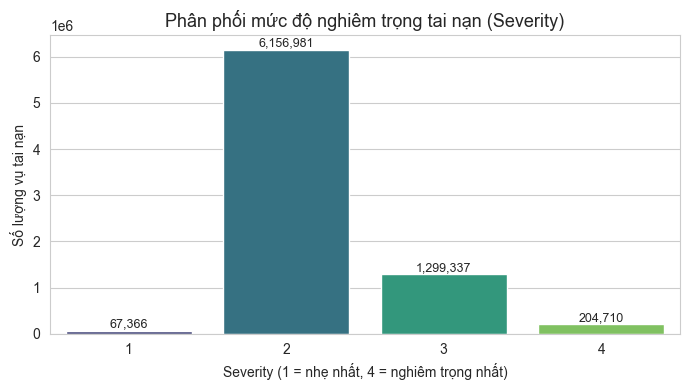

Nhận xét: dữ liệu mất cân bằng rõ rệt — Severity 2 chiếm 79.7%, trong khi Severity 1 chỉ chiếm 0.87%.
=> Ở bước modeling cần xử lý imbalance (class_weight / resampling) và đánh giá bằng F1-macro, không chỉ accuracy.


In [6]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(x='Severity', data=df, palette='viridis', order=sorted(df['Severity'].dropna().unique()))
plt.title('Phân phối mức độ nghiêm trọng tai nạn (Severity)')
plt.xlabel('Severity (1 = nhẹ nhất, 4 = nghiêm trọng nhất)')
plt.ylabel('Số lượng vụ tai nạn')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

sev_pct = df['Severity'].value_counts(normalize=True).sort_index() * 100
print(f'Nhận xét: dữ liệu mất cân bằng rõ rệt — Severity {sev_pct.idxmax()} chiếm {sev_pct.max():.1f}%, '
      f'trong khi Severity {sev_pct.idxmin()} chỉ chiếm {sev_pct.min():.2f}%.')
print('=> Ở bước modeling cần xử lý imbalance (class_weight / resampling) và đánh giá bằng F1-macro, không chỉ accuracy.')

### 2.2. Severity theo điều kiện thời tiết (liên quan RQ1)

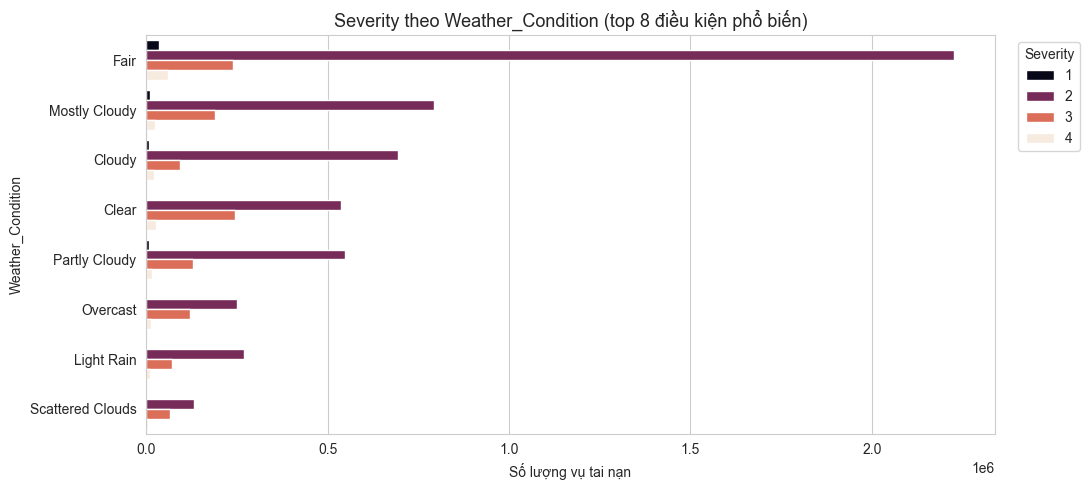

In [7]:
if 'Weather_Condition' in df.columns:
    top_weather = df['Weather_Condition'].value_counts().nlargest(8).index
    df_top_weather = df[df['Weather_Condition'].isin(top_weather)]

    plt.figure(figsize=(11, 5))
    sns.countplot(data=df_top_weather, y='Weather_Condition', hue='Severity',
                  order=top_weather, palette='rocket')
    plt.title('Severity theo Weather_Condition (top 8 điều kiện phổ biến)')
    plt.xlabel('Số lượng vụ tai nạn')
    plt.ylabel('Weather_Condition')
    plt.legend(title='Severity', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

### 2.3. Severity theo thời điểm trong ngày (Sunrise_Sunset) và tầm nhìn (Visibility)

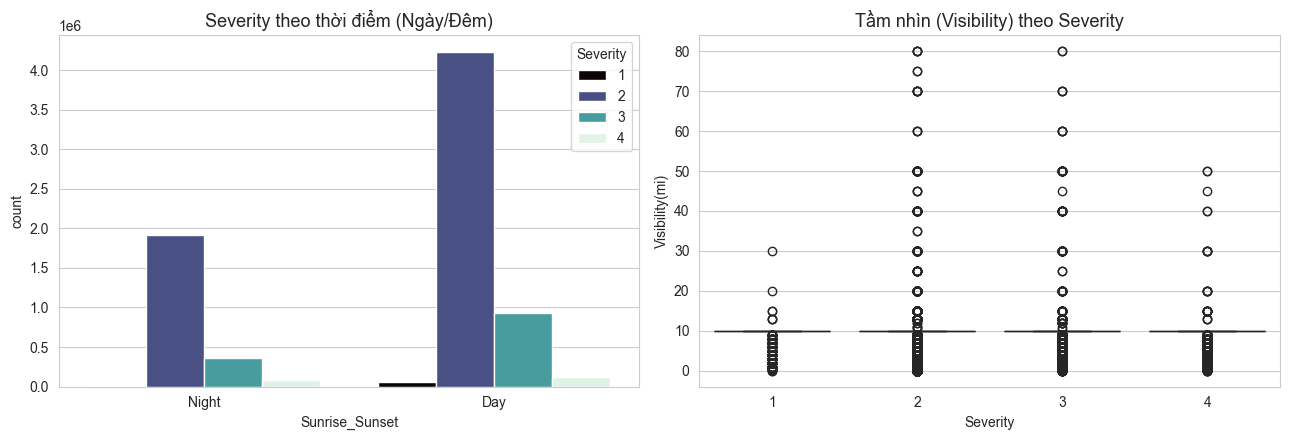

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

if 'Sunrise_Sunset' in df.columns:
    sns.countplot(data=df, x='Sunrise_Sunset', hue='Severity', ax=axes[0], palette='mako')
    axes[0].set_title('Severity theo thời điểm (Ngày/Đêm)')

if 'Visibility(mi)' in df.columns:
    sns.boxplot(data=df.sample(n=min(200_000, len(df)), random_state=42), x='Severity', y='Visibility(mi)', ax=axes[1], palette='mako')
    axes[1].set_title('Tầm nhìn (Visibility) theo Severity')

plt.tight_layout()
plt.show()

### 2.4. Tỷ lệ tai nạn nghiêm trọng cao theo hạ tầng đường (liên quan RQ1)

In [9]:
infra_cols = [c for c in ['Crossing', 'Junction', 'Traffic_Signal', 'Stop',
                           'Roundabout', 'Bump', 'Give_Way', 'Amenity', 'Railway'] if c in df.columns]

df['Severity_high'] = (df['Severity'] >= 3).astype(int)

infra_rate = pd.DataFrame({
    col: [
        df.loc[df[col] == True, 'Severity_high'].mean() if (df[col] == True).sum() > 0 else np.nan,
        df.loc[df[col] == False, 'Severity_high'].mean() if (df[col] == False).sum() > 0 else np.nan
    ]
    for col in infra_cols
}, index=['Có hạ tầng (True)', 'Không có (False)']).T

infra_rate = infra_rate.round(3)
print('Tỷ lệ Severity cao (3-4) theo từng loại hạ tầng đường:')
infra_rate

Tỷ lệ Severity cao (3-4) theo từng loại hạ tầng đường:


,Có hạ tầng (True),Không có (False)
Crossing,0.070,0.210
Junction,0.268,0.189
Traffic_Signal,0.095,0.212
Stop,0.062,0.198
Roundabout,0.044,0.195
Bump,0.096,0.195
Give_Way,0.162,0.195
Amenity,0.063,0.196
Railway,0.151,0.195


### 2.5. Ma trận tương quan các biến số

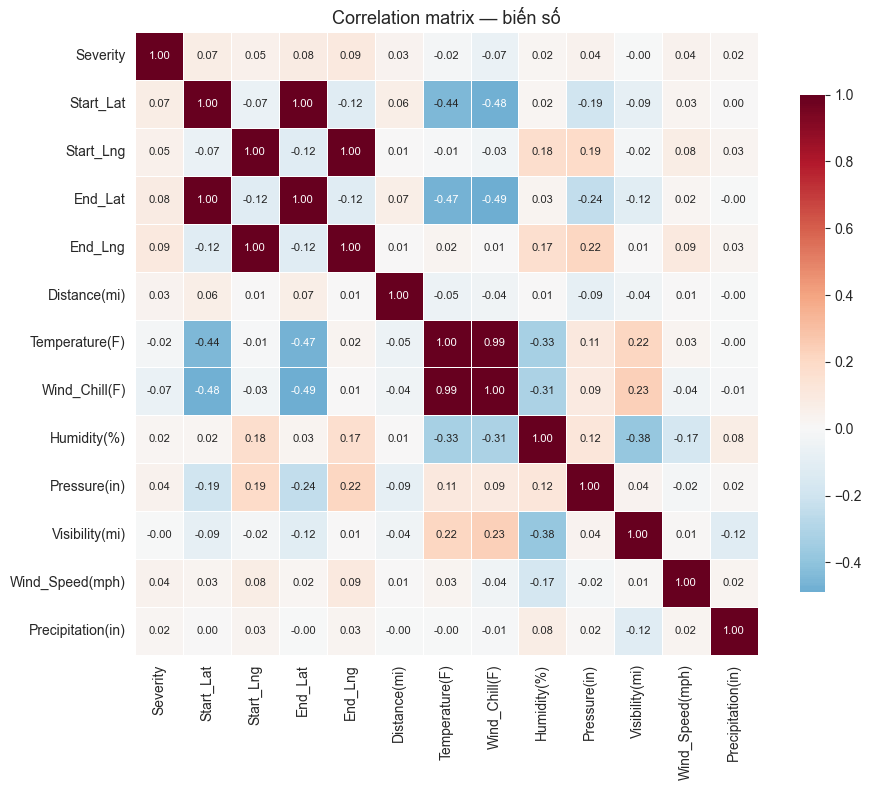

In [10]:
corr_cols = [c for c in numeric_cols if c not in ['Severity_high']]
plt.figure(figsize=(10, 8))
corr = df[corr_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8}, annot_kws={'size': 8})
plt.title('Correlation matrix — biến số')
plt.tight_layout()
plt.show()

## BƯỚC 3 — Xử lý Missing Data

### 3.1. Kiểm tra missing values

Các cột có missing values:


,Missing Count,Missing %
End_Lat,3402762,44.03
End_Lng,3402762,44.03
Precipitation(in),2203586,28.51
Wind_Chill(F),1999019,25.87
Wind_Speed(mph),571233,7.39
Visibility(mi),177098,2.29
Wind_Direction,175206,2.27
Humidity(%),174144,2.25
Weather_Condition,173459,2.24
Temperature(F),163853,2.12


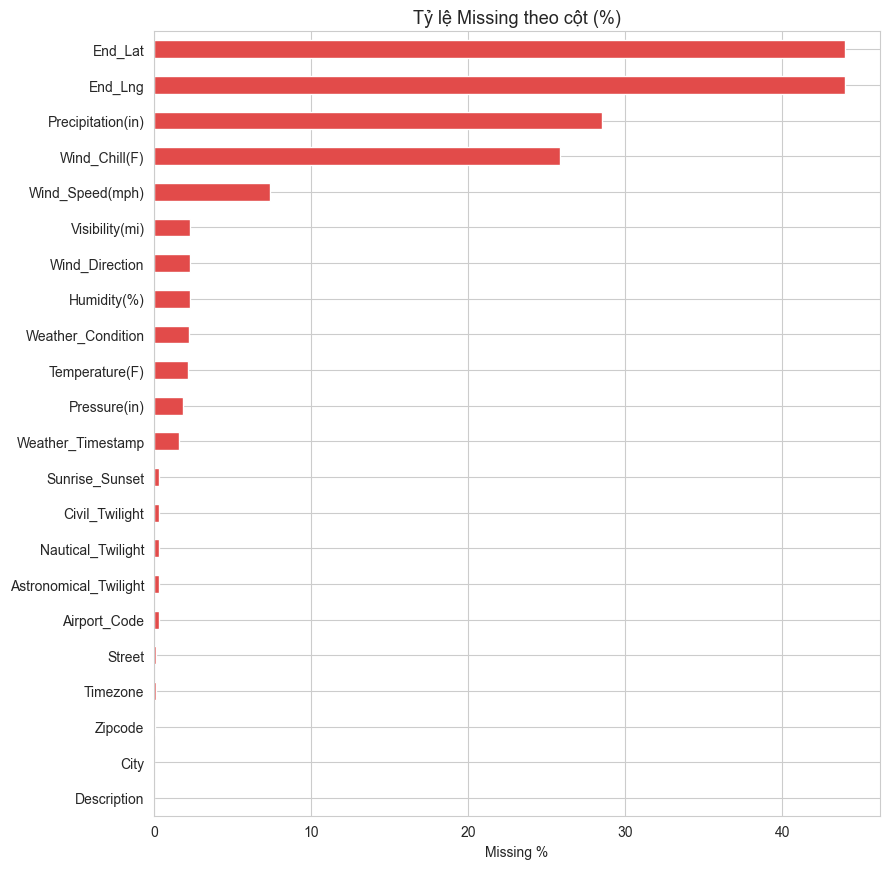

In [11]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

print('Các cột có missing values:')
display(missing_df)

if len(missing_df) > 0:
    plt.figure(figsize=(9, max(3, 0.4 * len(missing_df))))
    missing_df['Missing %'].plot(kind='barh', color='#E24B4A')
    plt.title('Tỷ lệ Missing theo cột (%)')
    plt.xlabel('Missing %')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print('Không có missing values trong dataset.')

### 3.2. Chiến lược xử lý missing

| Loại biến | Chiến lược |
|---|---|
| Cột có tỷ lệ missing >40% (`End_Lat`, `End_Lng`) | **Loại bỏ cột** |
| Cột văn bản / hằng số không dùng cho phân tích (`Description`, `Street`, `Country`, `Turning_Loop`, `Weather_Timestamp`) | **Loại bỏ cột** — không impute vì "mode" của văn bản tự do là vô nghĩa |
| Biến số liên tục (Temperature, Humidity, Pressure, Visibility, Wind_Speed) | Impute bằng **median theo nhóm `State`**, fallback median toàn cục |
| Biến phân loại (Weather_Condition, City, Zipcode, Timezone, Airport_Code, Wind_Direction, các cột Twilight) | Điền nhãn **`'Unknown'`** — không "bịa" giá trị bằng mode |
| `Sunrise_Sunset` | Suy ra từ giờ của `Start_Time` (6h–17h = Day, còn lại = Night) |
| Dòng thiếu `Severity` (target) | **Loại bỏ dòng** vì không thể dùng để huấn luyện/đánh giá |


In [12]:
df_clean = df.copy()

# 3.2.1 Loại bỏ dòng thiếu target
before = len(df_clean)
df_clean = df_clean.dropna(subset=['Severity'])
print(f'Đã loại {before - len(df_clean)} dòng thiếu Severity (target).')

# 3.2.2 Loại cột missing quá cao (>20%)
high_missing_cols = missing_df[missing_df['Missing %'] > 40].index.tolist()  
if high_missing_cols:
    df_clean = df_clean.drop(columns=high_missing_cols)
    print(f'Đã loại các cột missing > 40%: {high_missing_cols}')
else:
    print('Không có cột nào missing > 40%.')

# 3.2.3 Loại các cột văn bản tự do / hằng số không dùng cho phân tích
DROP_UNUSED_COLS = ['Description', 'Street', 'Country', 'Turning_Loop', 'Weather_Timestamp']
drop_now = [c for c in DROP_UNUSED_COLS if c in df_clean.columns]
df_clean = df_clean.drop(columns=drop_now)
print(f'Đã loại các cột không dùng: {drop_now}')

# --- Xóa Wind_Chill(F) nếu trùng thông tin với Temperature(F) ---
# Wind_Chill tính từ Temp + Wind_Speed, tương quan ~0.99 -> giữ Temperature là đủ
if 'Wind_Chill(F)' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Wind_Chill(F)'])
    print('Đã loại Wind_Chill(F) do trùng lặp cao với Temperature(F) (giữ Temperature)')


# 3.2.4 Xử lý riêng Precipitation(in) - giữ lại dù missing 28.51% vì cần cho RQ1 (liều lượng mưa)
if 'Precipitation(in)' in df_clean.columns and df_clean['Precipitation(in)'].isna().any():
    n_precip = int(df_clean['Precipitation(in)'].isna().sum())
    # Missing ở đây đa phần là không mưa / sensor không ghi -> điền 0 theo domain + tạo cờ cho tree model
    df_clean['precip_missing'] = df_clean['Precipitation(in)'].isna().astype('int8')
    df_clean['Precipitation(in)'] = df_clean['Precipitation(in)'].fillna(0)
    print(f'  Precipitation(in)   -> fillna(0) + tạo cờ precip_missing ({n_precip} dòng, 28.51% missing được giữ lại cho RQ1)')

# 3.2.5 Impute biến số liên tục bằng median theo State (fallback median toàn cục)
numeric_impute_cols = [c for c in ['Temperature(F)', 'Humidity(%)', 'Pressure(in)',
                                    'Visibility(mi)', 'Wind_Speed(mph)']
                        if c in df_clean.columns]

for col in numeric_impute_cols:
    n_missing = int(df_clean[col].isnull().sum())
    if n_missing == 0:
        continue
    state_median = df_clean.groupby('State')[col].transform('median')
    df_clean[col] = df_clean[col].fillna(state_median)
    global_median = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(global_median)
    print(f'  {col:<20} -> imputed {n_missing} values (median theo State, fallback global median = {global_median:.2f})')

# 3.2.6 Sunrise_Sunset: suy ra từ giờ của Start_Time (xấp xỉ: 6h-17h = Day)
if 'Sunrise_Sunset' in df_clean.columns:
    miss = df_clean['Sunrise_Sunset'].isnull()
    n_missing = int(miss.sum())
    if n_missing:
        hrs = pd.to_datetime(df_clean.loc[miss, 'Start_Time'], format='mixed', errors='coerce').dt.hour
        df_clean.loc[miss, 'Sunrise_Sunset'] = np.select(
            [hrs.isna().values, hrs.between(6, 17).values], ['Unknown', 'Day'], default='Night')
        print(f'  Sunrise_Sunset       -> derived {n_missing} values from Start_Time hour')

# 3.2.7 Biến phân loại: thiếu thông tin được giữ như một nhãn riêng 'Unknown'
categorical_unknown_cols = [c for c in ['Weather_Condition', 'City', 'Zipcode', 'Timezone',
                                         'Airport_Code', 'Wind_Direction', 'Civil_Twilight',
                                         'Nautical_Twilight', 'Astronomical_Twilight']
                            if c in df_clean.columns]
for col in categorical_unknown_cols:
    n_missing = int(df_clean[col].isnull().sum())
    if n_missing == 0:
        continue
    df_clean[col] = df_clean[col].fillna('Unknown')
    print(f'  {col:<22} -> filled {n_missing} values with "Unknown"')

# 3.2.8 Fallback an toàn: cột nào còn sót missing (số -> median, còn lại -> 'Unknown')
remaining_missing = df_clean.isnull().sum()
remaining_cols = remaining_missing[remaining_missing > 0].index.tolist()
if remaining_cols:
    print(f'\nXử lý fallback cho các cột còn sót missing: {remaining_cols}')
    for col in remaining_cols:
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            med = df_clean[col].median()
            df_clean[col] = df_clean[col].fillna(med)
            print(f'  {col:<20} -> fallback imputed median ({med})')
        else:
            df_clean[col] = df_clean[col].fillna('Unknown')
            print(f'  {col:<20} -> fallback filled "Unknown"')

print(f'\nTổng missing values còn lại: {df_clean.isnull().sum().sum()}')


Đã loại 0 dòng thiếu Severity (target).
Đã loại các cột missing > 40%: ['End_Lat', 'End_Lng']
Đã loại các cột không dùng: ['Description', 'Street', 'Country', 'Turning_Loop', 'Weather_Timestamp']
Đã loại Wind_Chill(F) do trùng lặp cao với Temperature(F) (giữ Temperature)
  Precipitation(in)   -> fillna(0) + tạo cờ precip_missing (2203586 dòng, 28.51% missing được giữ lại cho RQ1)
  Temperature(F)       -> imputed 163853 values (median theo State, fallback global median = 64.00)
  Humidity(%)          -> imputed 174144 values (median theo State, fallback global median = 67.00)
  Pressure(in)         -> imputed 140679 values (median theo State, fallback global median = 29.86)
  Visibility(mi)       -> imputed 177098 values (median theo State, fallback global median = 10.00)
  Wind_Speed(mph)      -> imputed 571233 values (median theo State, fallback global median = 7.00)
  Sunrise_Sunset       -> derived 23246 values from Start_Time hour
  Weather_Condition      -> filled 173459 values w

## BƯỚC 4 — Xử lý Outliers

Chiến lược gồm 2 lớp:

1. **Phát hiện** bằng **IQR** — chỉ dùng để thống kê/báo cáo, **không dùng để cắt dữ liệu**. Với dữ liệu thời tiết/tai nạn, nhiều giá trị cực đoan là có thật (rét đậm, gió mạnh, áp suất thấp khi có bão) và chính là tín hiệu cho RQ1; cắt theo IQR sẽ làm mất tín hiệu và làm hỏng các cờ ở Bước 5 (`high_wind`, `low_visibility`).
2. **Xử lý** chỉ với giá trị **bất khả thi về mặt vật lý** (lỗi sensor, ví dụ nhiệt độ 207°F, gió 1087 mph, áp suất 0 inHg): thay bằng median theo `State`. Không xóa dòng nên không mất vụ tai nạn nào.

`Distance(mi)` được giữ nguyên (chỉ đảm bảo không âm); việc xử lý biến này thuộc notebook modeling.

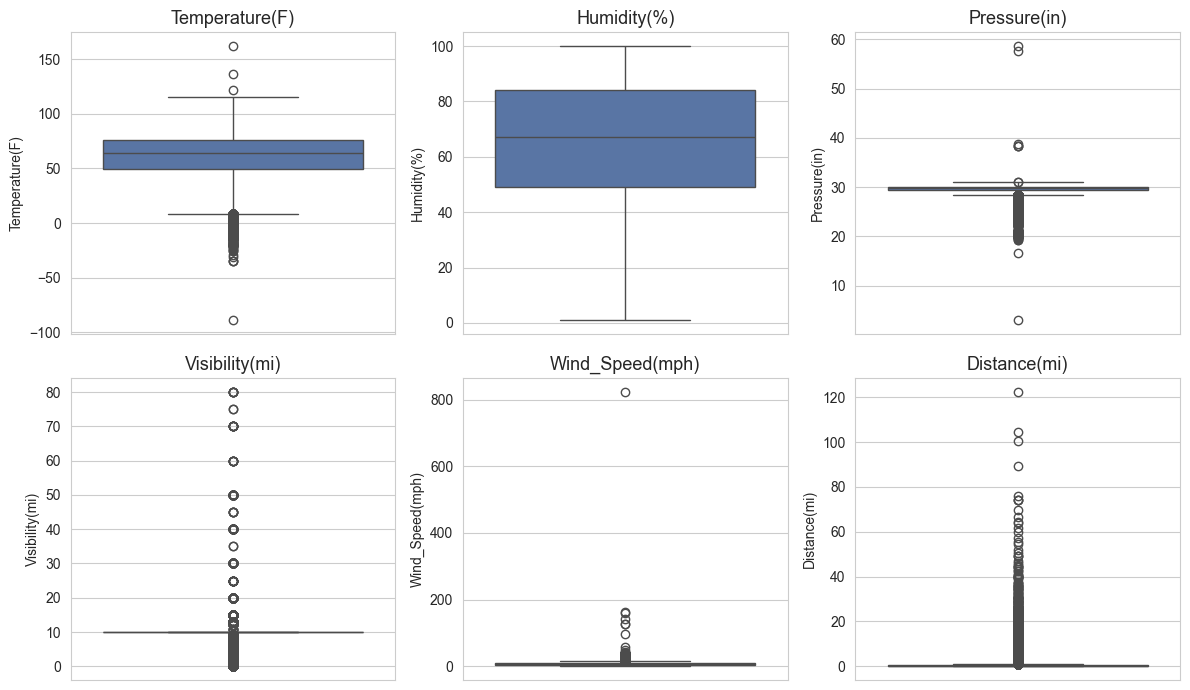

In [13]:
outlier_check_cols = [c for c in ['Temperature(F)', 'Humidity(%)', 'Pressure(in)',
                                   'Visibility(mi)', 'Wind_Speed(mph)', 'Distance(mi)']
                      if c in df_clean.columns]

# Vẽ trên mẫu 200k dòng cho nhanh (boxplot trên 7.7 triệu dòng rất chậm)
plot_df = df_clean[outlier_check_cols].sample(n=min(200_000, len(df_clean)), random_state=42)

n = len(outlier_check_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.5*nrows))
axes = np.array(axes).reshape(-1)
for i, col in enumerate(outlier_check_cols):
    sns.boxplot(y=plot_df[col], ax=axes[i], color='#4C72B0')
    axes[i].set_title(col)
for j in range(i+1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

In [14]:
def iqr_bounds(series, k=1.5):
    """Tính ngưỡng dưới và ngưỡng trên theo phương pháp IQR (chỉ để thống kê)."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# Ngưỡng hợp lệ về mặt vật lý — giá trị ngoài khoảng này là lỗi sensor
DOMAIN_LIMITS = {
    'Temperature(F)':  (-80, 135),   # xấp xỉ kỷ lục lạnh/nóng của Hoa Kỳ
    'Humidity(%)':     (0, 100),
    'Pressure(in)':    (24, 32),     # áp suất khí quyển thực tế (inHg)
    'Visibility(mi)':  (0, 100),
    'Wind_Speed(mph)': (0, 200),
}

outlier_summary = []
for col in outlier_check_cols:
    # --- Thống kê IQR (không dùng để sửa dữ liệu) ---
    lower, upper = iqr_bounds(df_clean[col])
    if upper - lower == 0:   # biến gần như hằng số (vd Visibility = 10): tính IQR trên phần không phải mode
        mode_val = df_clean[col].mode()[0]
        non_mode = df_clean.loc[df_clean[col] != mode_val, col]
        if len(non_mode) > 0:
            lower, upper = iqr_bounds(non_mode)
            lower, upper = min(lower, mode_val), max(upper, mode_val)
        else:
            lower, upper = df_clean[col].min(), df_clean[col].max()
    lower = max(lower, 0) if col in ['Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Distance(mi)'] else lower
    n_iqr = int(((df_clean[col] < lower) | (df_clean[col] > upper)).sum())

    # --- Xử lý: chỉ sửa giá trị bất khả thi về mặt vật lý ---
    n_invalid = 0
    if col in DOMAIN_LIMITS:
        lo, hi = DOMAIN_LIMITS[col]
        bad = (df_clean[col] < lo) | (df_clean[col] > hi)
        n_invalid = int(bad.sum())
        if n_invalid:
            df_clean.loc[bad, col] = np.nan
            state_median = df_clean.groupby('State')[col].transform('median')
            df_clean[col] = df_clean[col].fillna(state_median).fillna(df_clean[col].median())
    else:
        df_clean[col] = df_clean[col].clip(lower=0)   # Distance(mi): giữ nguyên, chỉ đảm bảo không âm

    outlier_summary.append({
        'column': col, 'iqr_lower': round(lower, 2), 'iqr_upper': round(upper, 2),
        'n_iqr_outliers': n_iqr, 'pct_iqr_outliers': round(n_iqr / len(df_clean) * 100, 2),
        'n_invalid_fixed': n_invalid
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
print('Tóm tắt outliers: IQR chỉ để thống kê; chỉ các giá trị bất khả thi về vật lý (n_invalid_fixed) được sửa.')
outlier_summary_df

Tóm tắt outliers: IQR chỉ để thống kê; chỉ các giá trị bất khả thi về vật lý (n_invalid_fixed) được sửa.


,column,iqr_lower,iqr_upper,n_iqr_outliers,pct_iqr_outliers,n_invalid_fixed
0,Temperature(F),11.00,115.00,65279,0.84,52
1,Humidity(%),0.00,136.50,0,0.00,0
2,Pressure(in),28.38,31.02,453621,5.87,30416
3,Visibility(mi),0.00,13.75,21008,0.27,15
4,Wind_Speed(mph),0.00,17.50,291148,3.77,34
5,Distance(mi),0.00,1.16,963606,12.47,0


## BƯỚC 5 — Feature engineering

Tạo đặc trưng thời gian, nhóm thời tiết, hạ tầng đường và các cờ điều kiện xấu. Các cờ `low_visibility` / `high_wind` được tạo từ dữ liệu **chưa bị cắt theo IQR** (xem Bước 4) nên vẫn giữ được tín hiệu.

In [15]:
# --- Thời gian ---
df_clean['Start_Time'] = pd.to_datetime(df_clean['Start_Time'], format='mixed', errors='coerce')
df_clean = df_clean.dropna(subset=['Start_Time', 'Severity'])

df_clean['hour']       = df_clean['Start_Time'].dt.hour.astype('int8')
df_clean['dayofweek']  = df_clean['Start_Time'].dt.dayofweek.astype('int8')
df_clean['month']      = df_clean['Start_Time'].dt.month.astype('int8')
df_clean['year']       = df_clean['Start_Time'].dt.year.astype('int16')
df_clean['is_weekend'] = (df_clean['dayofweek'] >= 5).astype('int8')
df_clean['is_rush_hour'] = df_clean['hour'].isin([7, 8, 9, 16, 17, 18]).astype('int8')
df_clean['season'] = ((df_clean['month'] % 12) // 3).astype('int8')   # 0=Winter 1=Spring 2=Summer 3=Fall

# --- Gom nhóm Weather_Condition (hơn 100 giá trị -> 9 nhóm) ---
# Thứ tự kiểm tra quan trọng: nhóm nguy hiểm/đặc biệt (Storm, Snow_Ice) kiểm tra trước nhóm chung (Rain, Cloudy)
def group_weather(s):
    s = str(s).lower()
    if s in ('unknown', 'nan', 'none', ''):                                          return 'Unknown'
    if any(k in s for k in ['thunder', 'storm', 'squall', 'tornado', 'funnel']):     return 'Storm'
    if any(k in s for k in ['snow', 'sleet', 'ice', 'hail', 'wintry', 'freezing']):  return 'Snow_Ice'
    if any(k in s for k in ['rain', 'drizzle', 'shower']):                           return 'Rain'
    if any(k in s for k in ['fog', 'mist', 'haze', 'smoke']):                        return 'Fog_LowVis'
    if 'dust' in s or 'sand' in s:                                                   return 'Dust_Sand'
    if 'cloud' in s or 'overcast' in s:                                              return 'Cloudy'
    if 'clear' in s or 'fair' in s:                                                  return 'Clear'
    return 'Other'

# Map trên các giá trị unique (nhanh hơn nhiều so với áp dụng cho từng dòng)
weather_map = {v: group_weather(v) for v in df_clean['Weather_Condition'].unique()}
df_clean['weather_group'] = df_clean['Weather_Condition'].map(weather_map).astype('category')

# --- Hạ tầng đường: 12 cờ boolean -> giữ nguyên + biến tổng hợp ---
INFRA = ['Amenity','Bump','Crossing','Give_Way','Junction','No_Exit','Railway',
         'Roundabout','Station','Stop','Traffic_Calming','Traffic_Signal']
for c in INFRA:
    df_clean[c] = df_clean[c].fillna(False).astype('int8')
df_clean['infra_count'] = df_clean[INFRA].sum(axis=1).astype('int8')

# --- Ngày/đêm ---
df_clean['is_night'] = (df_clean['Sunrise_Sunset'].astype(str) == 'Night').astype('int8')

# --- Điền thiếu đặc trưng thời tiết số (an toàn) ---
WEATHER_NUM = ['Temperature(F)','Humidity(%)','Pressure(in)','Visibility(mi)',
               'Wind_Speed(mph)']
for c in WEATHER_NUM:
    if df_clean[c].isna().any():
        print(f'  [warn] {c} còn {df_clean[c].isna().sum():,} missing -> điền median')
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())

# --- Cờ điều kiện xấu (phục vụ RQ1) ---
df_clean['low_visibility'] = (df_clean['Visibility(mi)'] < 2).astype('int8')
df_clean['high_wind']      = (df_clean['Wind_Speed(mph)'] > 20).astype('int8')

print('Đã tạo đầy đủ đặc trưng: thời gian, thời tiết, hạ tầng, điều kiện xấu')
print(f"  low_visibility = 1: {df_clean['low_visibility'].mean()*100:.2f}% | "
      f"high_wind = 1: {df_clean['high_wind'].mean()*100:.2f}%  (phải > 0%)")
print('  weather_group:', df_clean['weather_group'].value_counts().to_dict())
df_clean[['hour','dayofweek','month','year','season','is_weekend','is_rush_hour',
          'weather_group','infra_count','is_night',
          'low_visibility','high_wind']].head()

Đã tạo đầy đủ đặc trưng: thời gian, thời tiết, hạ tầng, điều kiện xấu
  low_visibility = 1: 3.18% | high_wind = 1: 1.97%  (phải > 0%)
  weather_group: {'Clear': 3405216, 'Cloudy': 3163728, 'Rain': 512097, 'Fog_LowVis': 201398, 'Snow_Ice': 179749, 'Unknown': 173459, 'Storm': 88729, 'Other': 3274, 'Dust_Sand': 744}


,hour,dayofweek,month,year,season,is_weekend,is_rush_hour,weather_group,infra_count,is_night,low_visibility,high_wind
0,5,0,2,2016,0,0,0,Rain,0,1,0,0
1,6,0,2,2016,0,0,0,Rain,0,1,0,0
2,6,0,2,2016,0,0,0,Cloudy,1,1,0,0
3,7,0,2,2016,0,0,1,Cloudy,0,1,0,0
4,7,0,2,2016,0,0,1,Cloudy,1,0,0,0


## BƯỚC 6 — Xử lý dữ liệu trùng lặp

Kiểm tra trùng lặp theo:
1. `ID` (phải là duy nhất)
2. "Khóa nghiệp vụ" của một vụ tai nạn: cùng `Start_Time`, `End_Time`, `Start_Lat`, `Start_Lng`, `Severity`, `Distance(mi)` nhưng **khác `ID`** — đây mới là kiểu trùng lặp thực sự có thể xảy ra (so sánh toàn bộ dòng kể cả `ID` luôn cho kết quả 0 vì `ID` luôn khác nhau).

In [16]:
n_id_dup = int(df_clean['ID'].duplicated().sum()) if 'ID' in df_clean.columns else 0
print(f'Số ID trùng lặp: {n_id_dup}')

DEDUP_KEY = [c for c in ['Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Severity', 'Distance(mi)']
             if c in df_clean.columns]
n_key_dup = int(df_clean.duplicated(subset=DEDUP_KEY).sum())
print(f'Số bản ghi trùng theo khóa nghiệp vụ {DEDUP_KEY}: {n_key_dup}')

before = len(df_clean)
if 'ID' in df_clean.columns:
    df_clean = df_clean.drop_duplicates(subset=['ID'], keep='first')
df_clean = df_clean.drop_duplicates(subset=DEDUP_KEY, keep='first')
after = len(df_clean)

print(f'\nĐã loại {before - after} dòng trùng lặp. Shape sau khi loại trùng: {df_clean.shape}')

Số ID trùng lặp: 0
Số bản ghi trùng theo khóa nghiệp vụ ['Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Severity', 'Distance(mi)']: 121561

Đã loại 121561 dòng trùng lặp. Shape sau khi loại trùng: (7606833, 52)


## BƯỚC 7 — Kiểm tra và Validate kết quả

Kiểm tra lại toàn bộ pipeline trước khi lưu:
1. Không còn missing values
2. Không còn `ID` trùng và bản ghi trùng theo khóa nghiệp vụ
3. Không còn giá trị bất khả thi về vật lý (theo `DOMAIN_LIMITS`), tọa độ nằm trong lãnh thổ Hoa Kỳ
4. Các cờ `low_visibility` / `high_wind` có cả giá trị 0 và 1 (không bị "chết")
5. Phân phối Severity không đổi bất thường so với trước xử lý

In [17]:
validation_report = {}

# 1. Missing values còn lại
validation_report['total_missing'] = int(df_clean.isnull().sum().sum())

# 2. Duplicate
validation_report['duplicate_id'] = int(df_clean['ID'].duplicated().sum())
validation_report['duplicate_key'] = int(df_clean.duplicated(subset=DEDUP_KEY).sum())

# 3. Kiểm tra range / logic của các biến then chốt
range_checks = {}
range_checks['Severity in [1,4]'] = bool(df_clean['Severity'].between(1, 4).all())
range_checks['hour in [0,23]'] = bool(df_clean['hour'].between(0, 23).all())
for col, (lo, hi) in DOMAIN_LIMITS.items():
    if col in df_clean.columns:
        range_checks[f'{col} in [{lo},{hi}]'] = bool(df_clean[col].between(lo, hi).all())
range_checks['Distance(mi) >= 0'] = bool((df_clean['Distance(mi)'] >= 0).all())
range_checks['Start_Lat in [24,50]'] = bool(df_clean['Start_Lat'].between(24, 50).all())
range_checks['Start_Lng in [-125,-66]'] = bool(df_clean['Start_Lng'].between(-125, -66).all())
range_checks['low_visibility có cả 0 và 1'] = df_clean['low_visibility'].nunique() == 2
range_checks['high_wind có cả 0 và 1'] = df_clean['high_wind'].nunique() == 2
validation_report['range_checks'] = range_checks

# 4. Kiểu dữ liệu
validation_report['dtypes_sample'] = df_clean.dtypes.astype(str).to_dict()

# 5. So sánh phân phối Severity trước/sau xử lý
severity_before = df['Severity'].value_counts(normalize=True).sort_index().round(4)
severity_after = df_clean['Severity'].value_counts(normalize=True).sort_index().round(4)
severity_compare = pd.DataFrame({'before': severity_before, 'after': severity_after})
max_diff = float((severity_after - severity_before).abs().max())
range_checks['Phân phối Severity lệch < 0.5 điểm %'] = max_diff < 0.005

print('=== VALIDATION REPORT ===')
print(f"Total missing values: {validation_report['total_missing']}")
print(f"Duplicate ID: {validation_report['duplicate_id']} | Duplicate (khóa nghiệp vụ): {validation_report['duplicate_key']}")
print('\nRange / logic checks:')
for k, v in range_checks.items():
    print(f"  [{'PASS' if v else 'FAIL'}] {k}")

print('\nSo sánh phân phối Severity trước/sau xử lý:')
display(severity_compare)

if validation_report['total_missing'] > 0:
    print('\n⚠️ Chi tiết các cột còn missing:')
    print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

assert validation_report['total_missing'] == 0, 'Vẫn còn missing values, cần kiểm tra lại Bước 3!'
assert validation_report['duplicate_id'] == 0 and validation_report['duplicate_key'] == 0, 'Vẫn còn dòng trùng lặp, cần kiểm tra lại Bước 6!'
assert all(range_checks.values()), 'Có range/logic check FAIL, xem danh sách ở trên!'
print('\n✔ Dữ liệu đã đạt yêu cầu validate, sẵn sàng để lưu.')

=== VALIDATION REPORT ===
Total missing values: 0
Duplicate ID: 0 | Duplicate (khóa nghiệp vụ): 0

Range / logic checks:
  [PASS] Severity in [1,4]
  [PASS] hour in [0,23]
  [PASS] Temperature(F) in [-80,135]
  [PASS] Humidity(%) in [0,100]
  [PASS] Pressure(in) in [24,32]
  [PASS] Visibility(mi) in [0,100]
  [PASS] Wind_Speed(mph) in [0,200]
  [PASS] Distance(mi) >= 0
  [PASS] Start_Lat in [24,50]
  [PASS] Start_Lng in [-125,-66]
  [PASS] low_visibility có cả 0 và 1
  [PASS] high_wind có cả 0 và 1
  [PASS] Phân phối Severity lệch < 0.5 điểm %

So sánh phân phối Severity trước/sau xử lý:


,before,after
Severity,,
1,0.0087,0.0086
2,0.7967,0.7949
3,0.1681,0.1701
4,0.0265,0.0264



✔ Dữ liệu đã đạt yêu cầu validate, sẵn sàng để lưu.


In [18]:
orig_cols, clean_cols = set(df.columns), set(df_clean.columns)
dropped_cols = [c for c in df.columns if c not in clean_cols]
new_cols = [c for c in df_clean.columns if c not in orig_cols]

print(f'Shape ban đầu (trước xử lý):  {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Shape sau xử lý (final):      {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')
print(f'\nSố cột bị loại: {len(dropped_cols)} -> {dropped_cols}')
print(f'Số cột mới tạo: {len(new_cols)} -> {new_cols}')
print('\nDanh sách toàn bộ cột trong dataset đã làm sạch:')
print(df_clean.columns.tolist())

Shape ban đầu (trước xử lý):  7,728,394 rows x 47 columns
Shape sau xử lý (final):      7,606,833 rows x 52 columns

Số cột bị loại: 8 -> ['End_Lat', 'End_Lng', 'Description', 'Street', 'Country', 'Weather_Timestamp', 'Wind_Chill(F)', 'Turning_Loop']
Số cột mới tạo: 13 -> ['precip_missing', 'hour', 'dayofweek', 'month', 'year', 'is_weekend', 'is_rush_hour', 'season', 'weather_group', 'infra_count', 'is_night', 'low_visibility', 'high_wind']

Danh sách toàn bộ cột trong dataset đã làm sạch:
['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Distance(mi)', 'City', 'County', 'State', 'Zipcode', 'Timezone', 'Airport_Code', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twi

## BƯỚC 8 — Lưu dữ liệu sạch (Save Clean Data)



In [19]:
OUTPUT_CSV = 'cleaned_us_accidents.csv'
OUTPUT_PARQUET = 'cleaned_us_accidents.parquet'

df_clean.to_csv(OUTPUT_CSV, index=False)
print(f'Saved: {OUTPUT_CSV}')

try:
    df_clean.to_parquet(OUTPUT_PARQUET, index=False)
    print(f'Saved: {OUTPUT_PARQUET} (khuyến nghị dùng cho các module sau vì đọc/ghi nhanh hơn với dữ liệu lớn)')
except Exception as e:
    print(f'Không lưu được parquet (thiếu thư viện pyarrow/fastparquet?): {e}')

print(f'\nFinal dataset: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')

Saved: cleaned_us_accidents.csv
Saved: cleaned_us_accidents.parquet (khuyến nghị dùng cho các module sau vì đọc/ghi nhanh hơn với dữ liệu lớn)

Final dataset: 7,606,833 rows x 52 columns


## Tổng kết Module 1 — Data Understanding

### Đã hoàn thành theo đúng 8 bước pipeline:
1. ✅ **Hiểu dữ liệu** — load dataset, xác định cấu trúc, phân nhóm biến, biến mục tiêu `Severity`
2. ✅ **EDA** — phân phối Severity, mối quan hệ với thời tiết/thời điểm/hạ tầng đường, correlation matrix
3. ✅ **Xử lý Missing Data** — loại dòng thiếu target, loại cột missing > 20% và cột văn bản không dùng, impute median theo `State` cho biến số, nhãn `'Unknown'` cho biến phân loại, suy `Sunrise_Sunset` từ giờ
4. ✅ **Xử lý Outliers** — IQR dùng để thống kê; chỉ thay các giá trị bất khả thi về vật lý (lỗi sensor) bằng median theo `State`, giữ nguyên giá trị cực đoan có thật (không xóa dòng nào)
5. ✅ **Feature Engineering** — time features (hour, dayofweek, month, year, season, is_weekend, is_rush_hour), `weather_group`, `infra_count`, `is_night`, cờ `low_visibility` / `high_wind`
6. ✅ **Xử lý trùng lặp** — kiểm tra và loại bỏ trùng `ID` và trùng theo khóa nghiệp vụ
7. ✅ **Validate kết quả** — missing = 0, không trùng lặp, range/logic hợp lệ, cờ điều kiện xấu không "chết", phân phối Severity ổn định
8. ✅ **Lưu dữ liệu sạch** — xuất `cleaned_us_accidents.csv` / `.parquet`

### Liên kết với 3 câu hỏi nghiên cứu (RQ):
| RQ | Đóng góp của Module 1 |
|----|------------------------|
| **RQ1** (điều kiện liên quan tới severity cao) | EDA mục 2.2–2.4 (thời tiết, thời điểm, hạ tầng) + feature engineering ở Bước 5 |
| **RQ2** (mô hình phân loại Severity) | Pipeline làm sạch + feature engineering ở Bước 3–5 tạo input cho modeling; encode và scale thực hiện ở Module 5 sau khi chia train/test để tránh data leakage |
| **RQ3** (bản đồ hotspot) | Giữ nguyên `Start_Lat`, `Start_Lng`; đã kiểm tra nằm trong lãnh thổ Hoa Kỳ ở Bước 7, phục vụ Module 3 |

> ⚠️ **Lưu ý cho Module 5 (modeling):** `Distance(mi)`, `End_Time` là thông tin chỉ biết sau khi tai nạn xảy ra, còn `Severity_high` được suy ra trực tiếp từ target — cần loại khỏi tập feature để tránh data leakage.